# Unit 4 Linear Regression with Scikit-Learn
This notebook completes the supplied fuel-consumption demo and Tasks A and B of the brief. I ran it on my own computer.

## Scope and corrections
The original notebook is unchanged; I worked on a copy. I corrected the demo in five places. Correlation now uses number columns only. The train and test split uses a fixed seed, so it is the same on every run. Predictions come from `test_x`, not `test_y`. `r2_score` receives the true values first. The mean squared error is labelled correctly. The China GDP file the demo needs was missing, so I took it from IBM's course storage.

The supplied GDP file holds total GDP, not GDP per person, and stops at 2020. I divided each year's GDP by that year's population before averaging, so the supplied-file analysis covers 2001 to 2020. For 2001 to 2021 I used a separate World Bank download and did not mix it with the older figures. I removed regional and income-group totals using the World Bank's country list. My main results use only economies with data for every year; averages over whatever years are available serve as a check on that choice.

In [146]:
from datetime import datetime, timezone
print("Run by Anne Dayer (student 39359) on my computer on",
      datetime.now(timezone.utc).strftime("%d %B %Y at %H:%M UTC"))

Run by Anne Dayer (student 39359) on my computer on 29 October 2026 at 17:16 UTC


In [147]:
from pathlib import Path
import json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy, sklearn, seaborn as sns
from scipy.stats import pearsonr, spearmanr
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
ROOT = Path.cwd()
OUT = ROOT / 'Unit4_ePortfolio_Exports'
OUT.mkdir(exist_ok=True)
def source_file(name):
    for path in [ROOT / 'sources' / name, ROOT / name]:
        if path.exists():
            return path
    raise FileNotFoundError(f'Place {name} beside this notebook or in the sources folder.')
def save_figure(name):
    plt.gcf().savefig(OUT / name, dpi=180, bbox_inches='tight')
versions = {name: mod.__version__ for name, mod in
            [('numpy', np), ('pandas', pd), ('scipy', scipy),
             ('sklearn', sklearn), ('seaborn', sns)]}
print('Package versions:', versions)

Package versions: {'numpy': '2.5.0', 'pandas': '3.1.0', 'scipy': '1.18.1', 'sklearn': '1.9.1', 'seaborn': '0.13.2'}


## Part 1: the supplied fuel-consumption demo, corrected

## Importing the required packages

In [148]:
import matplotlib.pyplot as plt
import pandas as pd
import pylab as pl
import numpy as np
import seaborn as sns

## Load the data

In [149]:
# Reading the data
df=pd.read_csv("FuelConsumption.csv")

In [150]:
# Take a look at the dataset
df.head(10)

,MODELYEAR,MAKE,MODEL,VEHICLECLASS,ENGINESIZE,CYLINDERS,TRANSMISSION,FUELTYPE,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
0,2014,ACURA,ILX,COMPACT,2.0,4,AS5,Z,9.9,6.7,8.5,33,196
1,2014,ACURA,ILX,COMPACT,2.4,4,M6,Z,11.2,7.7,9.6,29,221
2,2014,ACURA,ILX HYBRID,COMPACT,1.5,4,AV7,Z,6.0,5.8,5.9,48,136
3,2014,ACURA,MDX 4WD,SUV - SMALL,3.5,6,AS6,Z,12.7,9.1,11.1,25,255
4,2014,ACURA,RDX AWD,SUV - SMALL,3.5,6,AS6,Z,12.1,8.7,10.6,27,244
5,2014,ACURA,RLX,MID-SIZE,3.5,6,AS6,Z,11.9,7.7,10.0,28,230
6,2014,ACURA,TL,MID-SIZE,3.5,6,AS6,Z,11.8,8.1,10.1,28,232
7,2014,ACURA,TL AWD,MID-SIZE,3.7,6,AS6,Z,12.8,9.0,11.1,25,255
8,2014,ACURA,TL AWD,MID-SIZE,3.7,6,M6,Z,13.4,9.5,11.6,24,267
9,2014,ACURA,TSX,COMPACT,2.4,4,AS5,Z,10.6,7.5,9.2,31,212


In [151]:
df.corr(numeric_only=True)

,MODELYEAR,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_CITY,FUELCONSUMPTION_HWY,FUELCONSUMPTION_COMB,FUELCONSUMPTION_COMB_MPG,CO2EMISSIONS
MODELYEAR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ENGINESIZE,NaN,1.000000,0.934011,0.832225,0.778746,0.819482,-0.808554,0.874154
CYLINDERS,NaN,0.934011,1.000000,0.796473,0.724594,0.776788,-0.770430,0.849685
FUELCONSUMPTION_CITY,NaN,0.832225,0.796473,1.000000,0.965718,0.995542,-0.935613,0.898039
FUELCONSUMPTION_HWY,NaN,0.778746,0.724594,0.965718,1.000000,0.985804,-0.893809,0.861748
FUELCONSUMPTION_COMB,NaN,0.819482,0.776788,0.995542,0.985804,1.000000,-0.927965,0.892129
FUELCONSUMPTION_COMB_MPG,NaN,-0.808554,-0.770430,-0.935613,-0.893809,-0.927965,1.000000,-0.906394
CO2EMISSIONS,NaN,0.874154,0.849685,0.898039,0.861748,0.892129,-0.906394,1.000000


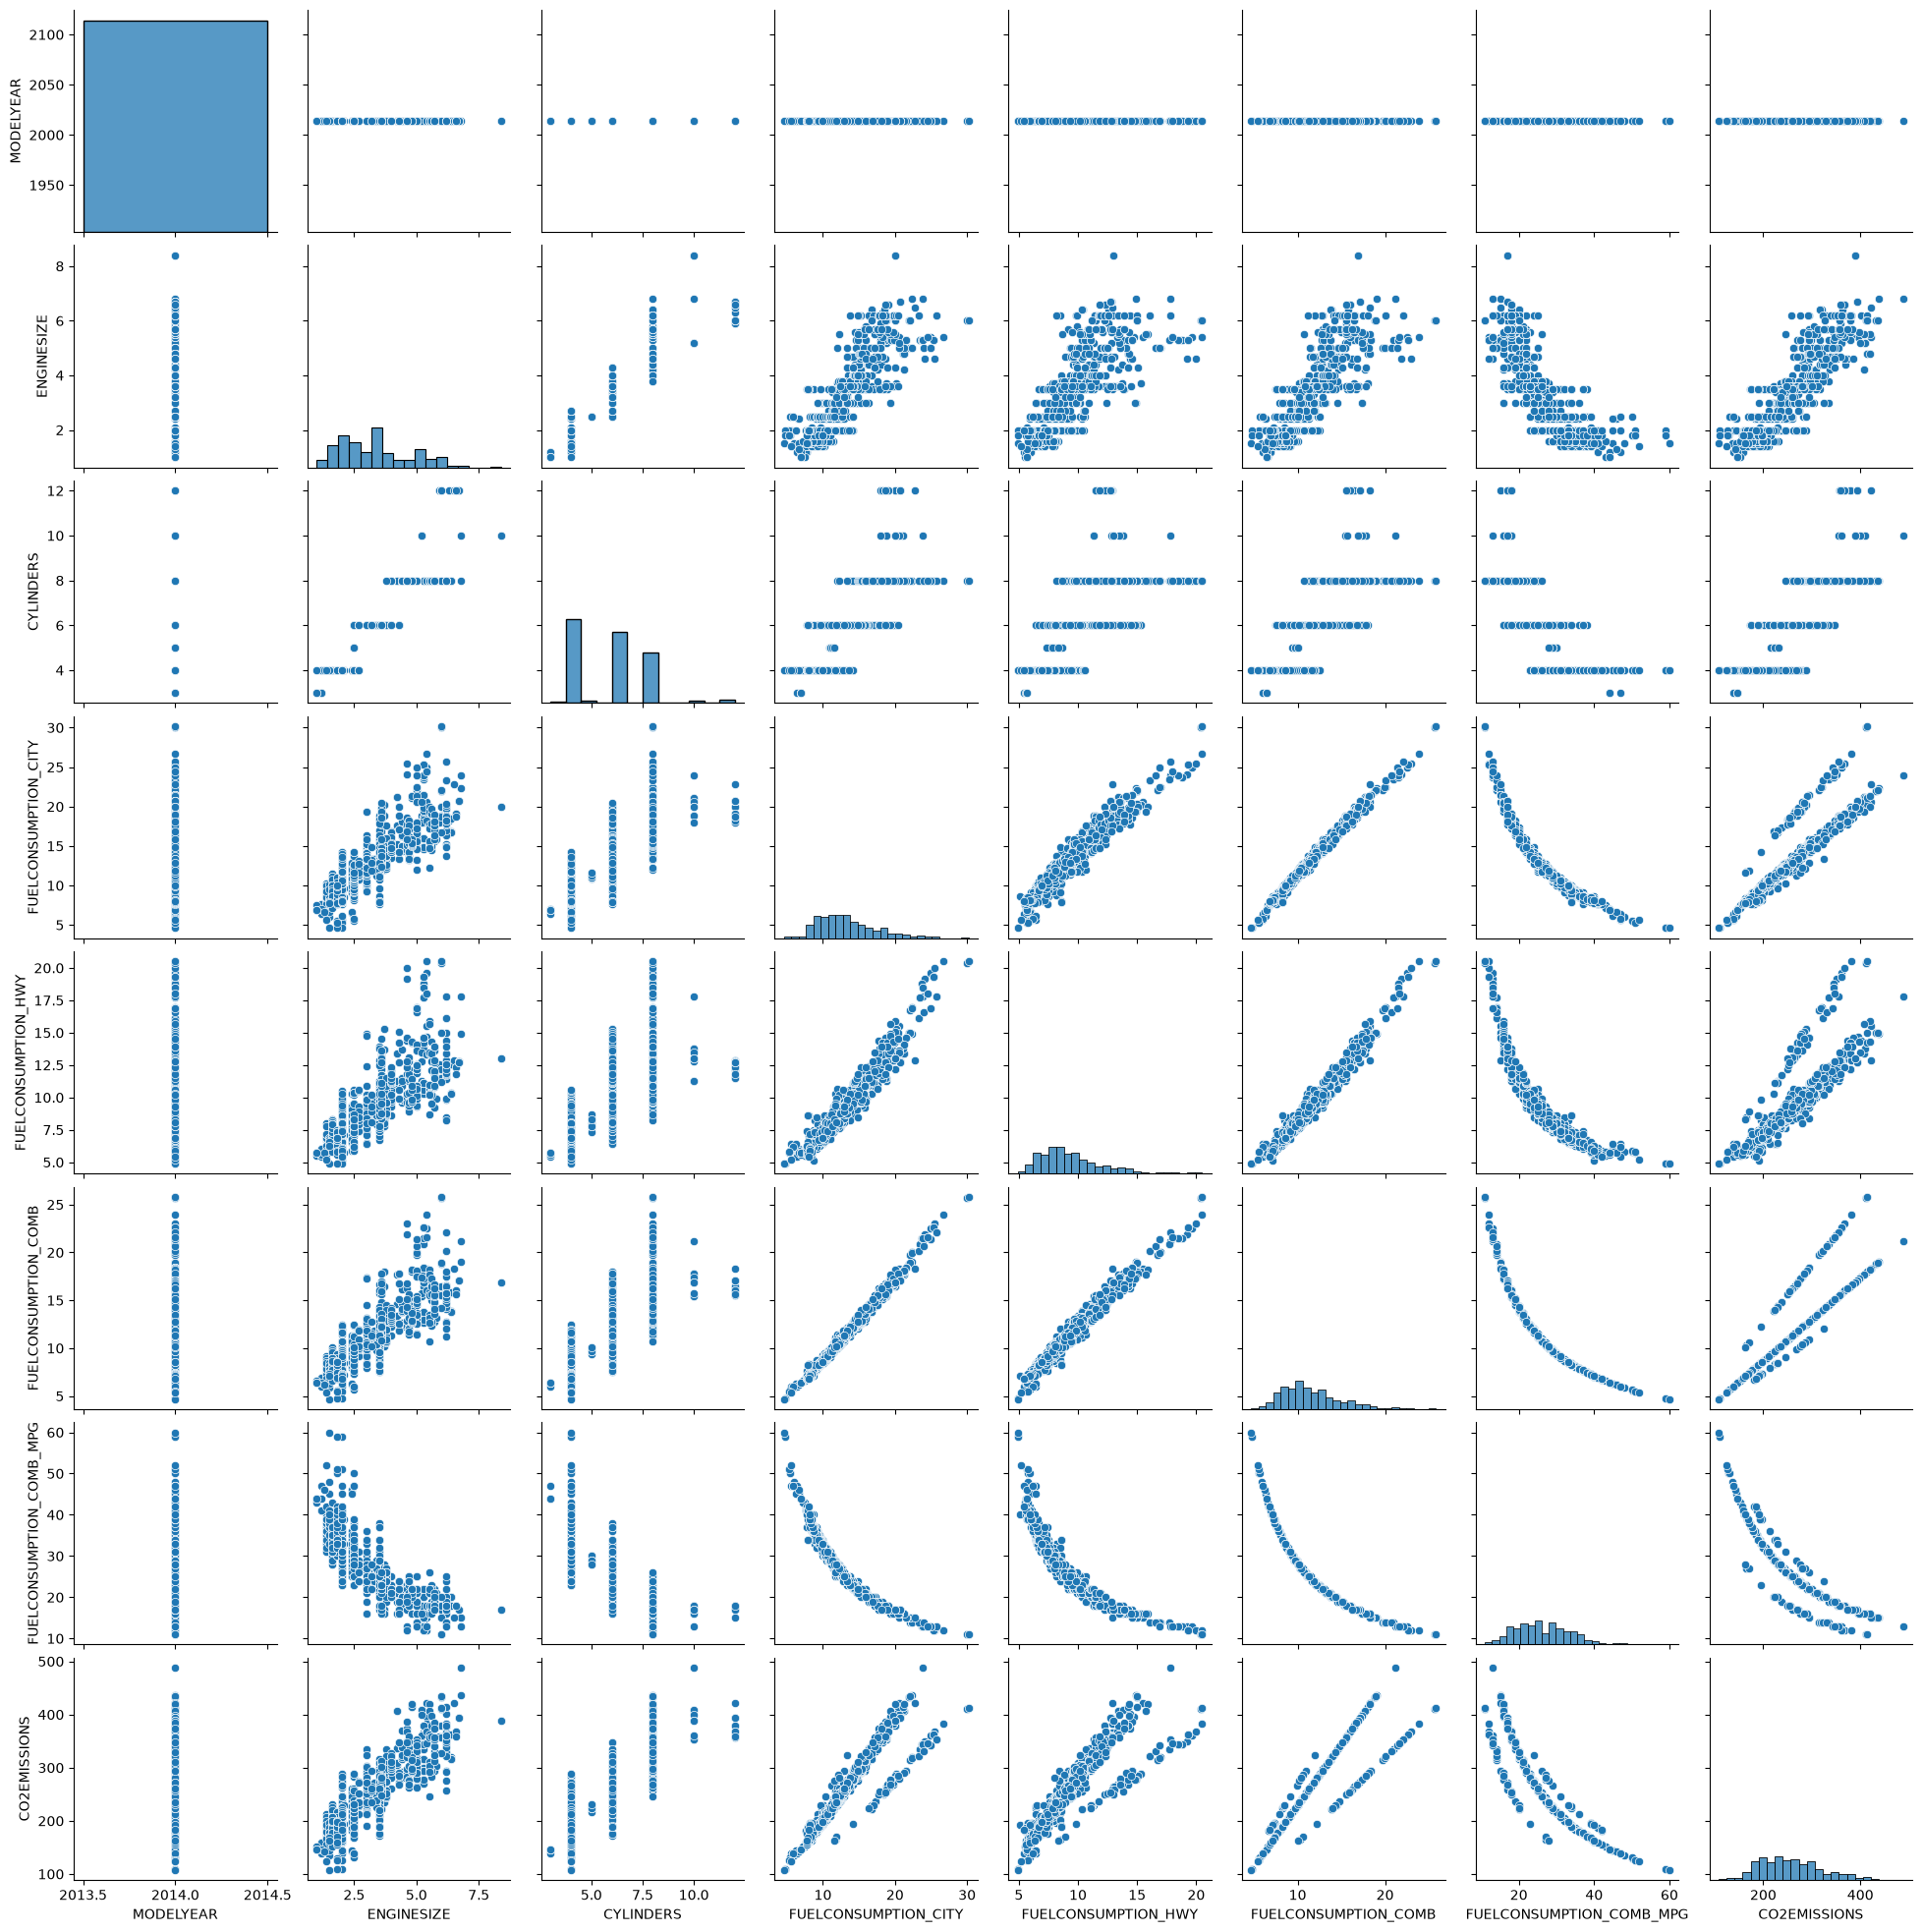

In [152]:
sns.pairplot(df.select_dtypes(include='number'), diag_kind='hist')
plt.show()

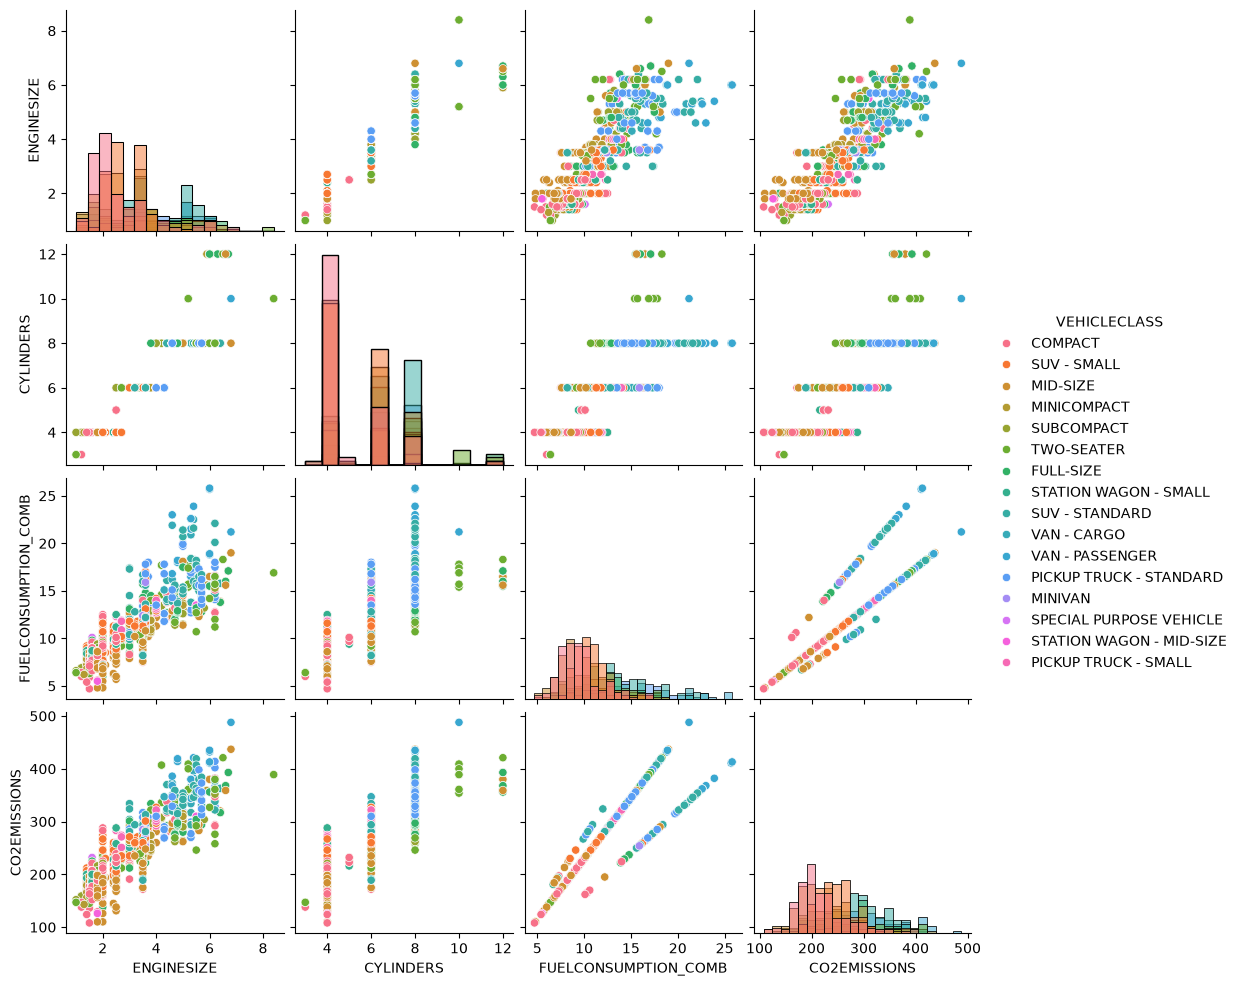

In [153]:
sns.pairplot(df, vars=['ENGINESIZE', 'CYLINDERS', 'FUELCONSUMPTION_COMB', 'CO2EMISSIONS'], hue='VEHICLECLASS', diag_kind='hist')
plt.show()

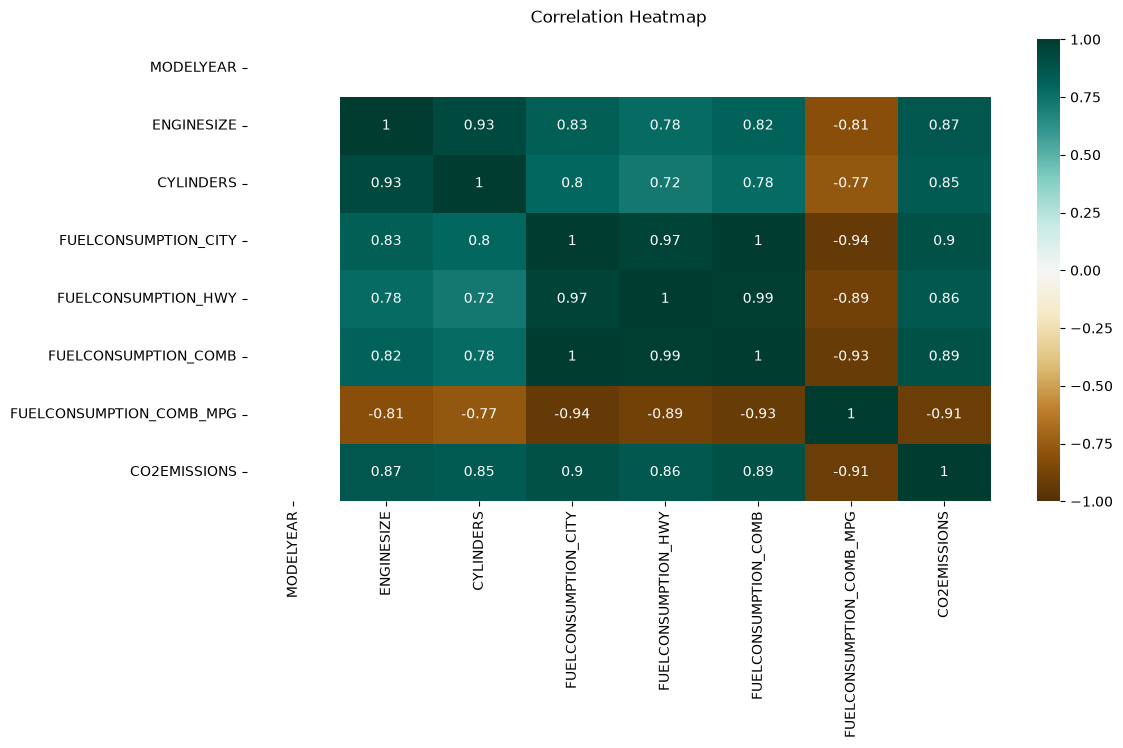

In [154]:
plt.figure(figsize=(12, 6))
heatmap = sns.heatmap(df.corr(numeric_only=True), vmin=-1, vmax=1, annot=True, cmap='BrBG')
heatmap.set_title('Correlation Heatmap', fontdict={'fontsize':12}, pad=12)
save_figure('01_fuel_correlation_heatmap.png')
plt.show()

## Plot to check the linearity

## Data exploration

In [155]:
# Summarise the data
print(df.describe())
cdf=df[['ENGINESIZE','CYLINDERS','FUELCONSUMPTION_COMB','CO2EMISSIONS']]
cdf.head(9)

       MODELYEAR   ENGINESIZE    CYLINDERS  FUELCONSUMPTION_CITY  \
count     1067.0  1067.000000  1067.000000           1067.000000   
mean      2014.0     3.346298     5.794752             13.296532   
std          0.0     1.415895     1.797447              4.101253   
min       2014.0     1.000000     3.000000              4.600000   
25%       2014.0     2.000000     4.000000             10.250000   
50%       2014.0     3.400000     6.000000             12.600000   
75%       2014.0     4.300000     8.000000             15.550000   
max       2014.0     8.400000    12.000000             30.200000   

       FUELCONSUMPTION_HWY  FUELCONSUMPTION_COMB  FUELCONSUMPTION_COMB_MPG  \
count          1067.000000           1067.000000               1067.000000   
mean              9.474602             11.580881                 26.441425   
std               2.794510              3.485595                  7.468702   
min               4.900000              4.700000                 11.000000 

,ENGINESIZE,CYLINDERS,FUELCONSUMPTION_COMB,CO2EMISSIONS
0,2.0,4,8.5,196
1,2.4,4,9.6,221
2,1.5,4,5.9,136
3,3.5,6,11.1,255
4,3.5,6,10.6,244
5,3.5,6,10.0,230
6,3.5,6,10.1,232
7,3.7,6,11.1,255
8,3.7,6,11.6,267


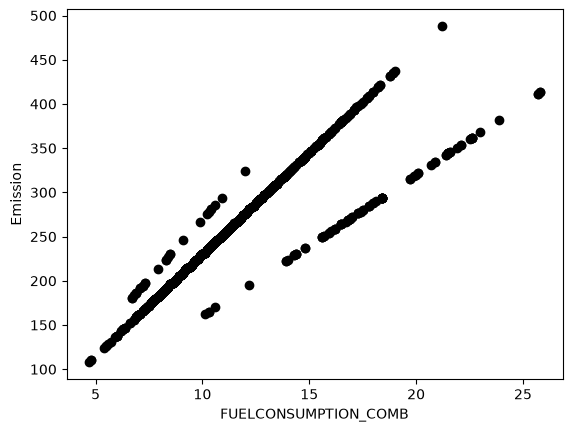

In [156]:
plt.scatter(cdf.FUELCONSUMPTION_COMB,cdf.CO2EMISSIONS, color='black')
plt.xlabel("FUELCONSUMPTION_COMB")
plt.ylabel("Emission")
plt.show()

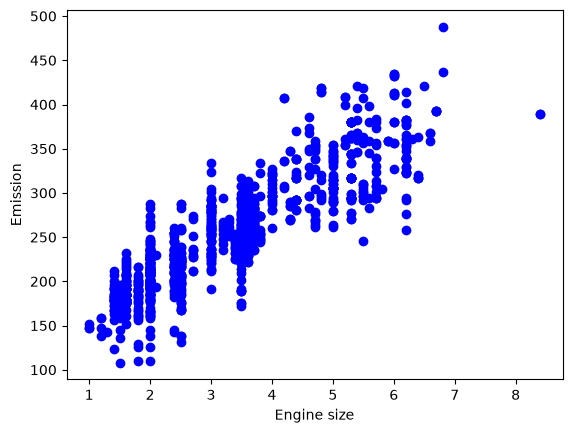

In [157]:
plt.scatter(cdf.ENGINESIZE,cdf.CO2EMISSIONS, color='blue')
plt.xlabel("Engine size")
plt.ylabel("Emission")
plt.show()

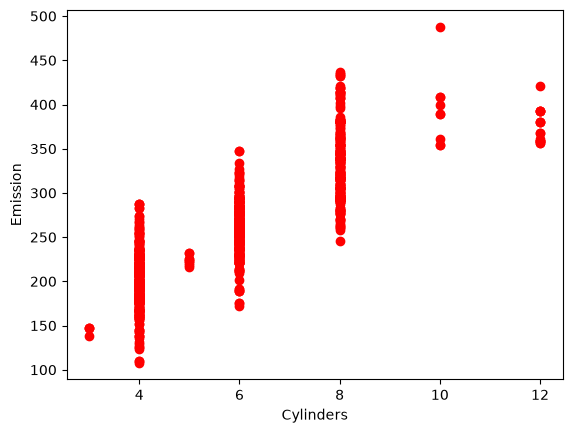

In [158]:
plt.scatter(cdf.CYLINDERS,cdf.CO2EMISSIONS, color='red')
plt.xlabel("Cylinders")
plt.ylabel("Emission")
plt.show()

Which of the above variables do you think will work best to explain a linear relation with CO2 emission?

Of the three inputs plotted, combined fuel consumption has the strongest Pearson correlation with CO2 (r = 0.8921), ahead of engine size (0.8742) and cylinders (0.8497). This does not show which input would predict best on new data. The supplied demo continues with engine size, and I followed it.

## Demo 2. Regression

## Train-test data preparation

In [159]:
np.random.seed(42)  # Fixed seed so the split is the same on every run
msk=np.random.rand(len(df))<0.8
train=cdf[msk]
test=cdf[~msk]

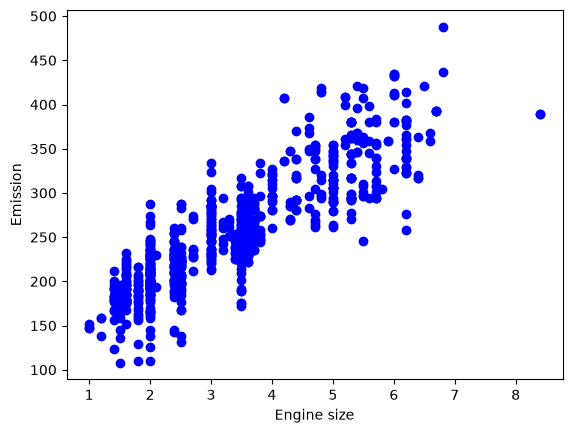

In [160]:
# Train data distribution
plt.scatter(train.ENGINESIZE,train.CO2EMISSIONS, color='blue')
plt.xlabel("Engine size")
plt.ylabel("Emission")
plt.show()

## Using sklearn package for data modelling

In [161]:
from sklearn import linear_model
regr=linear_model.LinearRegression()
train_x=np.asanyarray(train[['ENGINESIZE']])
train_y=np.asanyarray(train[['CO2EMISSIONS']])

regr.fit(train_x, train_y)
# The coefficients
print('Coefficients:', regr.coef_)
print('Intercept:', regr.intercept_)

Coefficients: [[39.526118]]
Intercept: [124.17604844]


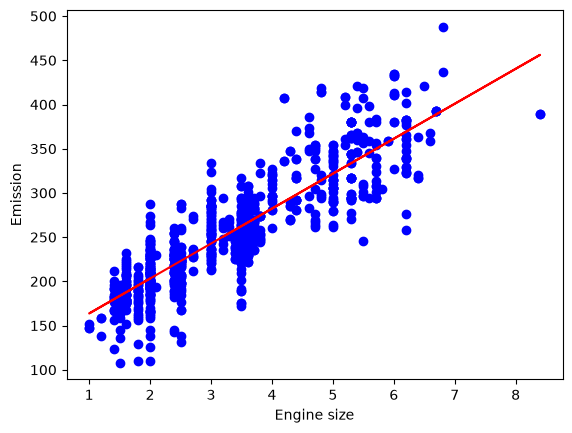

In [162]:
# Plot outputs
plt.scatter(train.ENGINESIZE,train.CO2EMISSIONS,color='blue')
plt.plot(train_x,regr.coef_[0][0]*train_x + regr.intercept_[0],'-r')
plt.xlabel("Engine size")
plt.ylabel("Emission")
save_figure('02_fuel_training_fit.png')
plt.show()

## Model evaluation

In [163]:
from sklearn.metrics import r2_score
test_x=np.asanyarray(test[['ENGINESIZE']])
test_y=np.asanyarray(test[['CO2EMISSIONS']])
test_y_ = regr.predict(test_x)

In [164]:
print("Mean absolute error: %.2f" % np.mean(np.absolute(test_y_-test_y)))
print("Mean squared error (MSE): %.2f" % np.mean((test_y_-test_y)**2))
print("R2-score: %.2f" % r2_score(test_y,test_y_))

Mean absolute error: 22.58
Mean squared error (MSE): 851.05
R2-score: 0.78


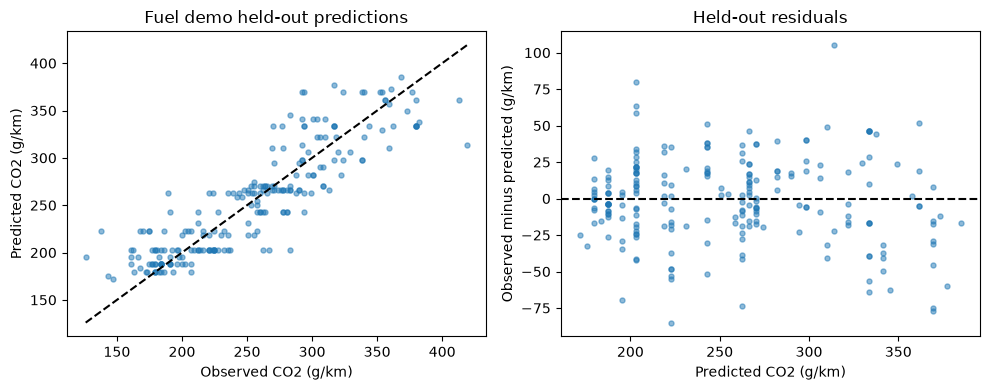

{
  "rows": 1067,
  "train_n": 848,
  "test_n": 219,
  "coefficient_g_per_km_per_litre": 39.526117997300126,
  "intercept_g_per_km": 124.17604843641709,
  "test_mae": 22.577106752193856,
  "test_mse": 851.048073913544,
  "test_rmse": 29.1727282562592,
  "test_r2": 0.7781857918313246,
  "baseline_mae": 51.49677457568709,
  "correlation_with_co2": {
    "ENGINESIZE": 0.8741543683958124,
    "CYLINDERS": 0.8496845920141154,
    "FUELCONSUMPTION_CITY": 0.8980385119353927,
    "FUELCONSUMPTION_HWY": 0.8617479448970436,
    "FUELCONSUMPTION_COMB": 0.8921285933157569,
    "FUELCONSUMPTION_COMB_MPG": -0.9063942295226142,
    "CO2EMISSIONS": 1.0
  }
}


In [165]:
fuel = pd.read_csv(ROOT / 'FuelConsumption.csv')
fuel_metrics = {
    'rows': len(fuel), 'train_n': len(train), 'test_n': len(test),
    'coefficient_g_per_km_per_litre': float(regr.coef_[0, 0]),
    'intercept_g_per_km': float(regr.intercept_[0]),
    'test_mae': float(mean_absolute_error(test_y, test_y_)),
    'test_mse': float(mean_squared_error(test_y, test_y_)),
    'test_rmse': float(np.sqrt(mean_squared_error(test_y, test_y_))),
    'test_r2': float(r2_score(test_y, test_y_)),
    'baseline_mae': float(mean_absolute_error(test_y, np.full_like(test_y, train_y.mean(), dtype=float))),
    'correlation_with_co2': fuel.select_dtypes(include='number').corr()['CO2EMISSIONS'].dropna().to_dict()
}
fuel_predictions = pd.DataFrame({'engine_size_l': test_x.ravel(),
    'observed_co2_g_km': test_y.ravel(), 'predicted_co2_g_km': test_y_.ravel()})
fuel_predictions.to_csv(OUT / 'fuel_test_predictions.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(test_y, test_y_, s=13, alpha=.5)
lo, hi = float(test_y.min()), float(test_y.max())
ax[0].plot([lo, hi], [lo, hi], 'k--')
ax[0].set(xlabel='Observed CO2 (g/km)', ylabel='Predicted CO2 (g/km)', title='Fuel demo held-out predictions')
ax[1].scatter(test_y_, test_y.ravel()-test_y_.ravel(), s=13, alpha=.5)
ax[1].axhline(0, color='black', linestyle='--')
ax[1].set(xlabel='Predicted CO2 (g/km)', ylabel='Observed minus predicted (g/km)', title='Held-out residuals')
fig.tight_layout(); save_figure('03_fuel_test_diagnostics.png'); plt.show()
print(json.dumps(fuel_metrics, indent=2))
# This test uses rows of the same 2014 table, not new years or new car models.

## Nonlinear regression

#### Importing required dataset

In [166]:
df=pd.read_csv(source_file("china_gdp.csv"))
df.head(10)

,Year,Value
0,1960,5.918412e+10
1,1961,4.955705e+10
2,1962,4.668518e+10
3,1963,5.009730e+10
4,1964,5.906225e+10
5,1965,6.970915e+10
6,1966,7.587943e+10
7,1967,7.205703e+10
8,1968,6.999350e+10
9,1969,7.871882e+10


#### Plotting the dataset

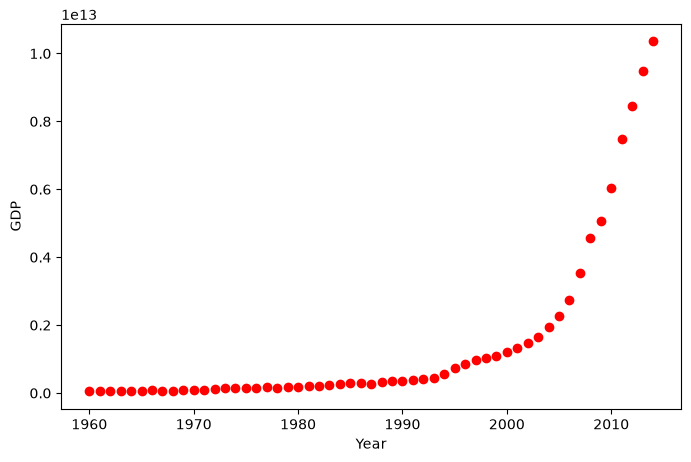

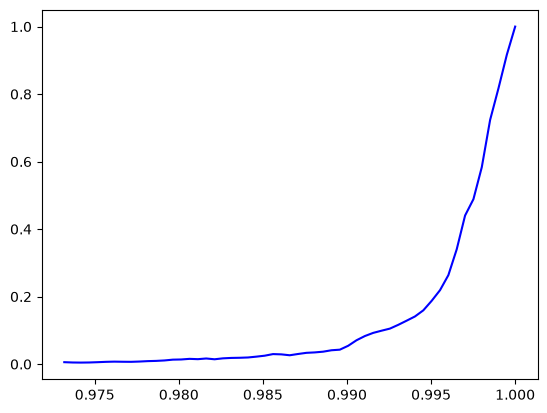

In [167]:
plt.figure(figsize=(8,5))
x_data,y_data=(df["Year"].values,df["Value"].values)
plt.plot(x_data,y_data,'ro')
plt.ylabel('GDP')
plt.xlabel('Year')
plt.show()
# Normalisation
xdata=x_data/max(x_data)
ydata=y_data/max(y_data)

plt.plot(xdata,ydata,'b')

The logistic curve rises slowly, then quickly, then levels off towards a ceiling. Its growth slows near the end, but the curve never turns down. Here it is a teaching example fitted to past GDP, not a tested model of economic growth.

#### Implement the logistic function

In [168]:
def sigmoid(x,Beta_1,Beta_2):
    y=1/(1+np.exp(-Beta_1*(x-Beta_2)))
    return y

#### Fit the logistic function on this dataset and estimate the relevant parameters

beta_1=690.451711,beta_2=0.997207


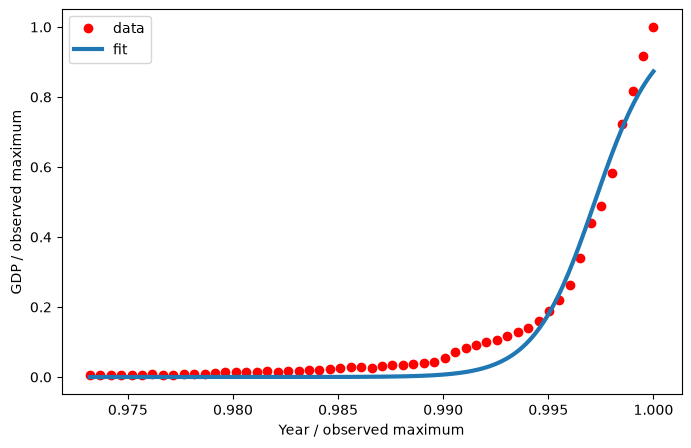

In [169]:
from scipy.optimize import curve_fit
popt,pcov=curve_fit(sigmoid,xdata,ydata)
print("beta_1=%f,beta_2=%f"%(popt[0],popt[1]))

##
x=np.linspace(x_data.min(), x_data.max(), 200)
x=x/max(x_data)
plt.figure(figsize=(8,5))
y=sigmoid(x,*popt)
plt.plot(xdata,ydata,'ro',label='data')
plt.plot(x,y,linewidth=3.0,label='fit')
plt.legend(loc='best')
plt.ylabel('GDP / observed maximum')
plt.xlabel('Year / observed maximum')
save_figure('04_china_sigmoid_demo.png')
plt.show()

## Part 2: Task A, preparing the data and Pearson correlation
I joined the GDP and population files on country code and checked that each code matched exactly one row, rather than relying on the row order. I removed the blank rows at the bottom of the files by checking the indicator code. GDP per person for a year is that year's GDP divided by that year's population. The means average these yearly values; they are not mean GDP divided by mean population. Using only economies with data for every year means each country is averaged over the same period, but it may favour countries with better records. The runs on all available years, and without China and India, show how much the result changes; they do not prove that it holds.

In [170]:
metadata = json.loads(source_file('world_bank_country_metadata.json').read_text(encoding='utf-8'))
assert metadata[0]['pages'] == 1
economies = {c['id']: c['name'] for c in metadata[1] if c['region']['id'] != 'NA'}
gdp = pd.read_csv(ROOT / 'Global_GDP.csv')
population_raw = pd.read_csv(ROOT / 'Global_Population.csv')
population = population_raw.loc[population_raw['Series Code'].eq('SP.POP.TOTL')].copy()
gdp = gdp.loc[gdp['Indicator Code'].eq('NY.GDP.MKTP.CD')].copy()
duplicates = population.loc[population['Country Code'].duplicated(keep=False)].copy()
duplicates.to_csv(OUT / 'supplied_population_conflicting_duplicates.csv', index=False)
# Aruba appears twice with different values. I keep the row with more years of data,
# rather than simply the first one, and save both rows so they can be checked.
population['_coverage'] = population[[str(y) for y in range(2001, 2022)]].notna().sum(axis=1)
population = population.sort_values('_coverage', ascending=False, kind='stable').drop_duplicates('Country Code').drop(columns='_coverage')
print('Conflicting duplicate country codes:', duplicates['Country Code'].unique().tolist())
print('Aruba: kept the row with more 2001–2021 values; the source does not say which is correct.')
assert gdp['Country Code'].is_unique and population['Country Code'].is_unique
years_requested = [str(y) for y in range(2001, 2022)]
years_supplied = [y for y in years_requested if y in gdp and y in population]
print('Requested years missing from supplied GDP:', sorted(set(years_requested)-set(gdp.columns)))
print('Footer and duplicate population rows removed:', len(population_raw)-len(population))
def prepare(gdp_wide, pop_wide, years, label):
    joined = gdp_wide.merge(pop_wide, on='Country Code', how='inner',
                           suffixes=('_gdp', '_pop'), validate='one_to_one')
    rows = []
    for _, row in joined.iterrows():
        country = row['Country Code']
        gv = pd.to_numeric(pd.Series([row[y+'_gdp'] for y in years]), errors='coerce')
        pv = pd.to_numeric(pd.Series([row[y+'_pop'] for y in years]), errors='coerce')
        valid = gv.notna() & pv.notna() & (pv > 0) & (gv >= 0)
        count = int(valid.sum())
        rows.append({'code': country, 'name': row['Country Name_gdp'],
                     'is_economy': country in economies, 'valid_years': count,
                     'mean_population': float(pv[valid].mean()) if count else np.nan,
                     'mean_gdp_per_capita': float((gv[valid]/pv[valid]).mean()) if count else np.nan,
                     'complete_period': count == len(years)})
    coverage = pd.DataFrame(rows)
    available = coverage.loc[coverage.is_economy & coverage.valid_years.gt(0)].copy()
    complete = available.loc[available.complete_period].copy()
    coverage.to_csv(OUT / (label+'_coverage.csv'), index=False)
    available.to_csv(OUT / (label+'_available_year_means.csv'), index=False)
    complete.to_csv(OUT / (label+'_complete_period_means.csv'), index=False)
    return coverage, available, complete
old_coverage, old_available, old_complete = prepare(gdp, population, years_supplied, 'supplied_2001_2020')
print('Supplied-file rows, available economies, complete economies:', len(old_coverage), len(old_available), len(old_complete))

Conflicting duplicate country codes: ['ABW']
Aruba: kept the row with more 2001–2021 values; the source does not say which is correct.
Requested years missing from supplied GDP: ['2021']
Footer and duplicate population rows removed: 6
Supplied-file rows, available economies, complete economies: 266 212 185


In [171]:
snapshot = json.loads(source_file('world_bank_2001_2021.json').read_text(encoding='utf-8'))
assert snapshot[0]['pages'] == 1 and len(snapshot[1]) == snapshot[0]['total']
iso2_to_code = {c['iso2Code']: c['id'] for c in metadata[1]}
# Five income-group totals have an empty country code in this download.
# I fill it from the World Bank's two-letter code before joining the files.
records = pd.DataFrame([{'Country Code': r['countryiso3code'] or iso2_to_code[r['country']['id']], 'Country Name': r['country']['value'],
                         'year': r['date'], 'indicator': r['indicator']['id'], 'value': r['value']}
                        for r in snapshot[1]])
assert not records.duplicated(['Country Code', 'year', 'indicator']).any()
def wide(indicator):
    return records.loc[records.indicator.eq(indicator)].pivot(
        index=['Country Code', 'Country Name'], columns='year', values='value').reset_index()
fresh_gdp, fresh_pop = wide('NY.GDP.MKTP.CD'), wide('SP.POP.TOTL')
new_coverage, new_available, new_complete = prepare(fresh_gdp, fresh_pop, years_requested, 'refreshed_2001_2021')
print('World Bank data update:', snapshot[0]['lastupdated'])
print('Refreshed rows, available economies, complete economies:', len(new_coverage), len(new_available), len(new_complete))
print('Aggregates excluded:', int((~new_coverage.is_economy).sum()))
print('Economies without 21 valid pairs:', int((new_coverage.is_economy & ~new_coverage.complete_period).sum()))
display(new_complete.head())

World Bank data update: 2026-10-08
Refreshed rows, available economies, complete economies: 266 214 201
Aggregates excluded: 49
Economies without 21 valid pairs: 16


,code,name,is_economy,valid_years,mean_population,mean_gdp_per_capita,complete_period
0,ABW,Aruba,True,21,1.024894e+05,25580.702662,True
2,AFG,Afghanistan,True,21,2.991144e+07,429.806126,True
4,AGO,Angola,True,21,2.475936e+07,3106.242184,True
5,ALB,Albania,True,21,2.836145e+06,4121.422723,True
6,AND,Andorra,True,21,7.581843e+04,40472.930020,True


## Part 3: Task B, linear regression
X is the mean population in millions; y is the mean yearly GDP per person in current US dollars. Using millions changes the units of the slope, not the line itself. These fits describe the countries in the data. Their R² is measured on the same data the line was fitted to, so it is not a prediction score; for that, I added a separate 80/20 split as a limited check. A relationship here does not mean that population causes GDP per person.

In [172]:
def fit_summary(frame):
    x = frame['mean_population'].to_numpy(dtype=float)/1e6
    y = frame['mean_gdp_per_capita'].to_numpy(dtype=float)
    model = LinearRegression().fit(x.reshape(-1, 1), y)
    predictions = model.predict(x.reshape(-1, 1))
    result = {'n': len(frame), 'pearson_r': float(pearsonr(x, y).statistic),
              'spearman_rho': float(spearmanr(x, y).statistic),
              'slope_usd_per_million_people': float(model.coef_[0]),
              'intercept_usd_per_person': float(model.intercept_),
              'in_sample_r2': float(r2_score(y, predictions))}
    return result, model, x, y, predictions
cases = {'supplied_complete_2001_2020': old_complete,
         'supplied_available_2001_2020': old_available,
         'refreshed_complete_2001_2021': new_complete,
         'refreshed_available_2001_2021': new_available,
         'refreshed_complete_without_CHN_IND': new_complete.loc[~new_complete.code.isin(['CHN', 'IND'])]}
global_results = {name: fit_summary(frame)[0] for name, frame in cases.items()}
global_result, global_model, gx, gy, fitted = fit_summary(new_complete)
pd.DataFrame(global_results).T.to_csv(OUT / 'global_correlation_regression_results.csv')
print(pd.DataFrame(global_results).T.round(5).to_string())
main_predictions = new_complete.copy()
main_predictions['fitted_gdp_per_capita'] = fitted
main_predictions['residual'] = gy-fitted
main_predictions.to_csv(OUT / 'global_main_predictions.csv', index=False)

                                        n  pearson_r  spearman_rho  slope_usd_per_million_people  intercept_usd_per_person  in_sample_r2
supplied_complete_2001_2020         185.0   -0.04947      -0.15029                      -6.51804               13212.55363       0.00245
supplied_available_2001_2020        212.0   -0.06780      -0.28672                     -11.97988               16006.16285       0.00460
refreshed_complete_2001_2021        201.0   -0.06668      -0.28233                     -11.65603               15830.87671       0.00445
refreshed_available_2001_2021       214.0   -0.07044      -0.32212                     -12.72920               16320.27418       0.00496
refreshed_complete_without_CHN_IND  199.0   -0.05894      -0.27829                     -32.37728               16258.78610       0.00347


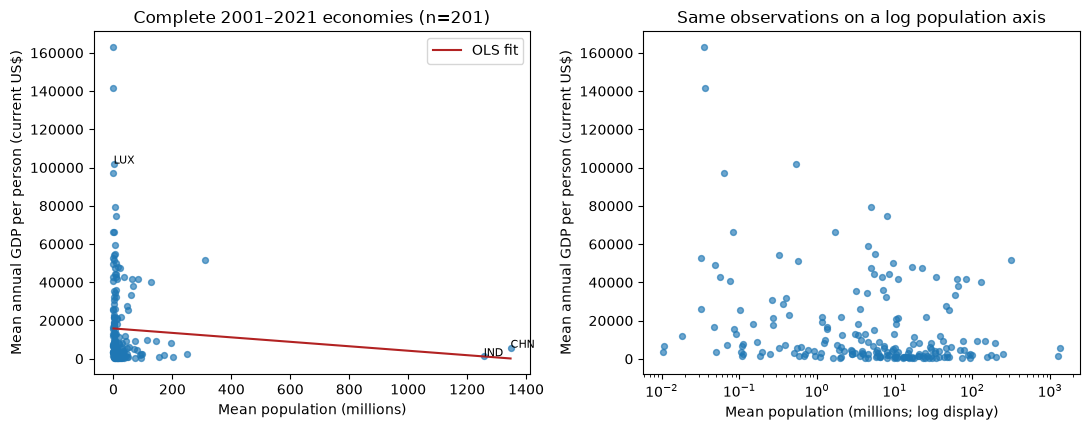

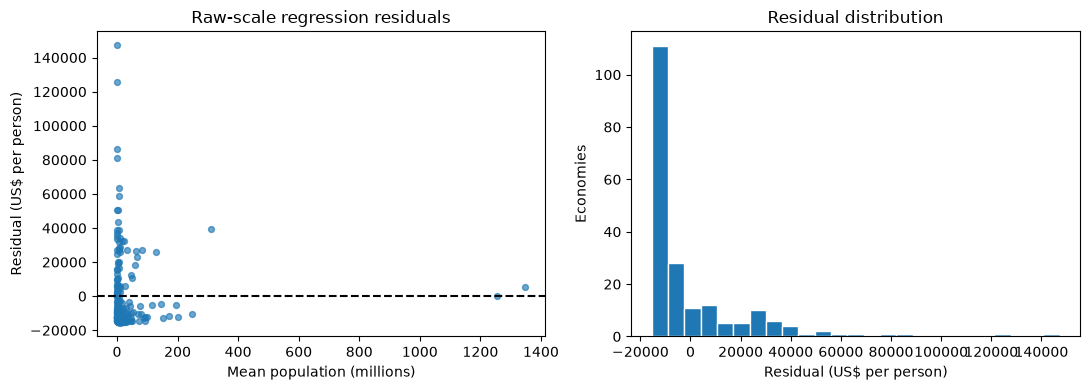

In [173]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
order = np.argsort(gx)
ax[0].scatter(gx, gy, s=18, alpha=.65)
ax[0].plot(gx[order], fitted[order], color='firebrick', label='OLS fit')
ax[0].set(xlabel='Mean population (millions)', ylabel='Mean annual GDP per person (current US$)',
          title=f"Complete 2001–2021 economies (n={len(gx)})")
ax[0].legend()
ax[1].scatter(gx, gy, s=18, alpha=.65)
ax[1].set_xscale('log')
ax[1].set(xlabel='Mean population (millions; log display)',
          ylabel='Mean annual GDP per person (current US$)', title='Same observations on a log population axis')
for code_value in ['CHN','IND','LUX']:
    row = new_complete.loc[new_complete.code.eq(code_value)]
    if len(row):
        ax[0].annotate(code_value, (float(row.mean_population.iloc[0]/1e6),float(row.mean_gdp_per_capita.iloc[0])), fontsize=8)
fig.tight_layout(); save_figure('05_global_population_gdp_fit.png'); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(gx, gy-fitted, s=18, alpha=.65); ax[0].axhline(0, color='black', linestyle='--')
ax[0].set(xlabel='Mean population (millions)', ylabel='Residual (US$ per person)', title='Raw-scale regression residuals')
ax[1].hist(gy-fitted, bins=25, edgecolor='white')
ax[1].set(xlabel='Residual (US$ per person)', ylabel='Economies', title='Residual distribution')
fig.tight_layout(); save_figure('06_global_residual_diagnostics.png'); plt.show()

In [174]:
indices = np.arange(len(new_complete))
itrain, itest = train_test_split(indices, test_size=.2, random_state=42)
held_model = LinearRegression().fit(gx[itrain].reshape(-1, 1), gy[itrain])
held_predictions = held_model.predict(gx[itest].reshape(-1, 1))
baseline = np.full(len(itest), gy[itrain].mean())
global_holdout = {'train_n': len(itrain), 'test_n': len(itest),
    'r2': float(r2_score(gy[itest], held_predictions)),
    'mae': float(mean_absolute_error(gy[itest], held_predictions)),
    'baseline_mae': float(mean_absolute_error(gy[itest], baseline))}
print('Separate economy holdout check:', global_holdout)
metrics = {'execution_scope': 'Local execution',
    'packages': versions, 'fuel': fuel_metrics, 'global_cases': global_results,
    'global_holdout': global_holdout, 'world_bank_lastupdated': snapshot[0]['lastupdated'],
    'coverage': {'supplied_rows': len(old_coverage), 'supplied_complete': len(old_complete),
        'supplied_available': len(old_available), 'fresh_rows': len(new_coverage),
        'fresh_complete': len(new_complete), 'fresh_available': len(new_available),
        'aggregates_excluded': int((~new_coverage.is_economy).sum()),
        'incomplete_economies': int((new_coverage.is_economy & ~new_coverage.complete_period).sum())}}
(OUT / 'Unit4_metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
print('Saved charts, tables and metrics to', OUT.name)

Separate economy holdout check: {'train_n': 160, 'test_n': 41, 'r2': -0.0376745940703358, 'mae': 14530.864616169665, 'baseline_mae': 14860.19372754155}
Saved charts, tables and metrics to Unit4_ePortfolio_Exports


## Interpretation and limitations
Pearson's r measures how close a relationship is to a straight line. It does not show cause and can miss a curve. Population alone predicts GDP per person poorly. Small wealthy countries and very large ones stretch the scale and pull the line; leaving out China and India is one check on this. Keeping only complete records drops countries with gaps, which can bias the result. Current dollars include inflation and exchange-rate changes. GDP per person says nothing about how income is shared, so national figures must not be applied to individuals. The fuel split is a teaching exercise: almost identical versions of one car can fall on both sides of it. The China curve is a fit to past data, not a tested forecast.

## Sources
- Géron, A. (2025) *Hands-On Machine Learning with Scikit-Learn and PyTorch*. Santa Rosa: O’Reilly.
- IBM (no date) *China GDP Teaching Dataset* [Dataset]. Available at: https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/ML0101ENv3/labs/china_gdp.csv (Accessed: 24 October 2026).
- scikit-learn developers (no date) *r2_score*. Available at: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html (Accessed: 24 October 2026).
- World Bank (2026a) *World Development Indicators: GDP (current US\$), population and economy metadata* [Dataset]. Indicator codes NY.GDP.MKTP.CD and SP.POP.TOTL. Data update 8 October 2026. Available at: https://data.worldbank.org/indicator/NY.GDP.MKTP.CD and https://data.worldbank.org/indicator/SP.POP.TOTL (Accessed: 24 October 2026).
- World Bank (2026b) *GDP (current US\$): licence CC BY 4.0*. Available at: https://data.worldbank.org/indicator/NY.GDP.MKTP.CD (Accessed: 24 October 2026).

Supplied materials: University of Essex Unit 4 Seminar brief, demo notebook, FuelConsumption.csv, Global_GDP.csv and Global_Population.csv.